In [1]:
# !pip install --user --upgrade --no-cache-dir "torch>=2.7" "torchvision>=0.22" --index-url https://download.pytorch.org/whl/cu128

In [2]:
import torch
print(torch.__version__, torch.version.cuda)        # 2.11.0+cu128  12.8
print(torch.cuda.get_arch_list())                   # should include 'sm_120'
torch.randn(2, 2, device="cuda") @ torch.randn(2, 2, device="cuda")

2.11.0+cu128 12.8
['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']


tensor([[-0.2900, -2.3228],
        [ 0.3196,  1.2405]], device='cuda:0')

In [3]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt

import torch.nn as nn
import torch.optim as optim
import torchvision.utils as vutils
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True   # some WikiArt files are truncated

import ignite
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.__version__, ignite.__version__)

cuda 2.11.0+cu128 0.5.5


In [4]:
import os, shutil

os.environ["KAGGLEHUB_CACHE"] = "/tmp/kagglehub"   # MUST be set before importing kagglehub
import kagglehub
print("Cache folder:", kagglehub.config.get_cache_folder())   # must say /tmp/kagglehub
print("Free in /tmp: %.0f GB" % (shutil.disk_usage("/tmp").free / 1e9))

path = kagglehub.dataset_download("steubk/wikiart")
print(path, os.listdir(path)[:10])
DATA_ROOT = path

Cache folder: /tmp/kagglehub
Free in /tmp: 1292 GB


100%|██████████| 31.4G/31.4G [05:22<00:00, 104MB/s]   

Extracting files...


/tmp/kagglehub/datasets/steubk/wikiart/versions/1 ['Abstract_Expressionism', 'Action_painting', 'Analytical_Cubism', 'Art_Nouveau_Modern', 'Baroque', 'Color_Field_Painting', 'Contemporary_Realism', 'Cubism', 'Early_Renaissance', 'Expressionism']


In [5]:
SEED        = 42
SUBSET_SIZE = 30000      # None = use all ~80k images (much slower)
IMAGE_SIZE  = 64
BATCH_SIZE  = 128
NZ          = 100        # latent vector size
NGF         = 64         # generator feature maps
NDF         = 64         # discriminator feature maps
NC          = 3          # RGB
NUM_EPOCHS  = 25
LR          = 2e-4
BETA1       = 0.5
NUM_WORKERS = 2

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("samples", exist_ok=True)

Images used: 30000


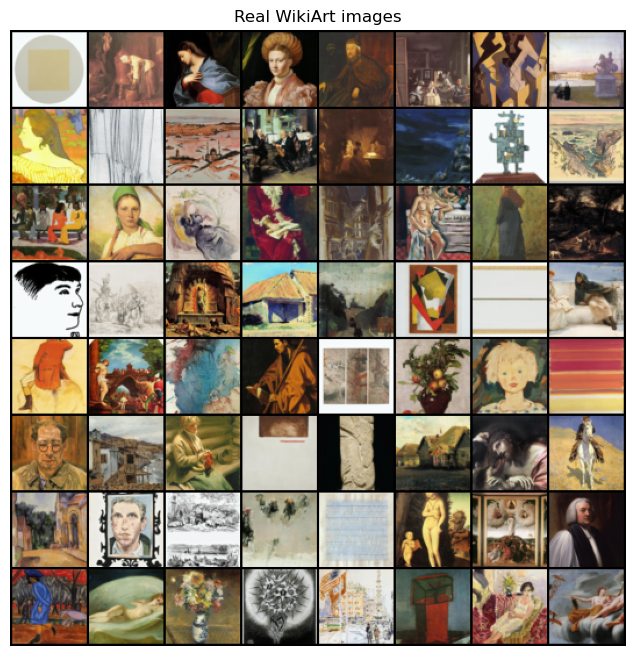

In [6]:
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3),
])

full_ds = datasets.ImageFolder(DATA_ROOT, transform=transform)
if SUBSET_SIZE is not None and SUBSET_SIZE < len(full_ds):
    idx = np.random.choice(len(full_ds), SUBSET_SIZE, replace=False)
    dataset = Subset(full_ds, idx)
else:
    dataset = full_ds

dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=NUM_WORKERS, drop_last=True, pin_memory=True)
print("Images used:", len(dataset))

real_batch = next(iter(dataloader))
plt.figure(figsize=(8, 8)); plt.axis("off"); plt.title("Real WikiArt images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0][:64], padding=2, normalize=True), (1, 2, 0)))
plt.show()

In [7]:
def weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(NZ, NGF*8, 4, 1, 0, bias=False), nn.BatchNorm2d(NGF*8), nn.ReLU(True),      # 4x4
            nn.ConvTranspose2d(NGF*8, NGF*4, 4, 2, 1, bias=False), nn.BatchNorm2d(NGF*4), nn.ReLU(True),   # 8x8
            nn.ConvTranspose2d(NGF*4, NGF*2, 4, 2, 1, bias=False), nn.BatchNorm2d(NGF*2), nn.ReLU(True),   # 16x16
            nn.ConvTranspose2d(NGF*2, NGF, 4, 2, 1, bias=False), nn.BatchNorm2d(NGF), nn.ReLU(True),       # 32x32
            nn.ConvTranspose2d(NGF, NC, 4, 2, 1, bias=False), nn.Tanh()                                    # 64x64
        )
    def forward(self, z):
        return self.main(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(NC, NDF, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),                              # 32
            nn.Conv2d(NDF, NDF*2, 4, 2, 1, bias=False), nn.BatchNorm2d(NDF*2), nn.LeakyReLU(0.2, inplace=True),    # 16
            nn.Conv2d(NDF*2, NDF*4, 4, 2, 1, bias=False), nn.BatchNorm2d(NDF*4), nn.LeakyReLU(0.2, inplace=True),  # 8
            nn.Conv2d(NDF*4, NDF*8, 4, 2, 1, bias=False), nn.BatchNorm2d(NDF*8), nn.LeakyReLU(0.2, inplace=True),  # 4
            nn.Conv2d(NDF*8, 1, 4, 1, 0, bias=False)   # logits (use BCEWithLogitsLoss)
        )
    def forward(self, x):
        return self.main(x).view(-1)

netG = Generator().to(device);     netG.apply(weights_init)
netD = Discriminator().to(device); netD.apply(weights_init)
print(netG); print(netD)

criterion  = nn.BCEWithLogitsLoss()
optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))
fixed_noise = torch.randn(64, NZ, 1, 1, device=device)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


In [8]:
G_losses, D_losses = [], []
real_label, fake_label = 0.9, 0.0   # one-sided label smoothing

start = time.time()
for epoch in range(NUM_EPOCHS):
    netG.train(); netD.train()
    for i, (real, _) in enumerate(dataloader):
        real = real.to(device, non_blocking=True)
        b = real.size(0)

        # Update D: maximize log D(x) + log(1 - D(G(z)))
        netD.zero_grad()
        out_real = netD(real)
        lossD_real = criterion(out_real, torch.full((b,), real_label, device=device))
        noise = torch.randn(b, NZ, 1, 1, device=device)
        fake = netG(noise)
        out_fake = netD(fake.detach())
        lossD_fake = criterion(out_fake, torch.full((b,), fake_label, device=device))
        lossD = lossD_real + lossD_fake
        lossD.backward()
        optimizerD.step()

        # Update G: maximize log D(G(z))
        netG.zero_grad()
        out = netD(fake)
        lossG = criterion(out, torch.ones(b, device=device))
        lossG.backward()
        optimizerG.step()

        G_losses.append(lossG.item()); D_losses.append(lossD.item())
        if i % 100 == 0:
            print(f"[{epoch+1}/{NUM_EPOCHS}][{i}/{len(dataloader)}] "
                  f"Loss_D {lossD.item():.4f}  Loss_G {lossG.item():.4f}  "
                  f"D(x) {torch.sigmoid(out_real).mean():.3f}  D(G(z)) {torch.sigmoid(out_fake).mean():.3f}")

    netG.eval()
    with torch.no_grad():
        samp = netG(fixed_noise).cpu()
    vutils.save_image(samp, f"samples/epoch_{epoch+1:03d}.png", nrow=8, normalize=True)
    torch.save(netG.state_dict(), "netG.pth"); torch.save(netD.state_dict(), "netD.pth")

print(f"Training done in {(time.time()-start)/60:.1f} min")

[1/25][0/234] Loss_D 1.7747  Loss_G 7.2273  D(x) 0.639  D(G(z)) 0.624
[1/25][100/234] Loss_D 1.1373  Loss_G 1.8837  D(x) 0.458  D(G(z)) 0.075
[1/25][200/234] Loss_D 0.4455  Loss_G 5.2275  D(x) 0.841  D(G(z)) 0.049
[2/25][0/234] Loss_D 0.5020  Loss_G 4.0304  D(x) 0.801  D(G(z)) 0.084
[2/25][100/234] Loss_D 0.6165  Loss_G 4.2364  D(x) 0.764  D(G(z)) 0.104
[2/25][200/234] Loss_D 0.8002  Loss_G 2.3226  D(x) 0.657  D(G(z)) 0.218
[3/25][0/234] Loss_D 1.0233  Loss_G 1.7734  D(x) 0.477  D(G(z)) 0.170
[3/25][100/234] Loss_D 0.9580  Loss_G 4.2623  D(x) 0.846  D(G(z)) 0.381
[3/25][200/234] Loss_D 0.7818  Loss_G 2.3813  D(x) 0.595  D(G(z)) 0.135
[4/25][0/234] Loss_D 1.2412  Loss_G 2.0849  D(x) 0.323  D(G(z)) 0.015
[4/25][100/234] Loss_D 1.0313  Loss_G 4.2789  D(x) 0.725  D(G(z)) 0.395
[4/25][200/234] Loss_D 0.6530  Loss_G 2.5540  D(x) 0.653  D(G(z)) 0.107
[5/25][0/234] Loss_D 0.6259  Loss_G 3.8903  D(x) 0.661  D(G(z)) 0.080
[5/25][100/234] Loss_D 0.4896  Loss_G 4.4805  D(x) 0.884  D(G(z)) 0.117
[5

Loss Curve

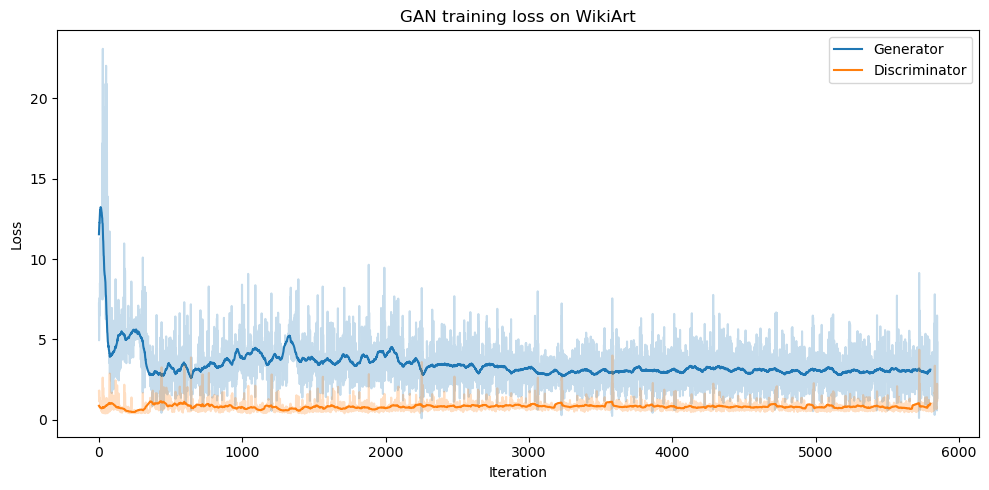

In [9]:
def smooth(x, k=50):
    return np.convolve(x, np.ones(k)/k, mode="valid")

plt.figure(figsize=(10, 5))
plt.plot(G_losses, alpha=0.25, color="C0"); plt.plot(smooth(G_losses), color="C0", label="Generator")
plt.plot(D_losses, alpha=0.25, color="C1"); plt.plot(smooth(D_losses), color="C1", label="Discriminator")
plt.xlabel("Iteration"); plt.ylabel("Loss"); plt.title("GAN training loss on WikiArt")
plt.legend(); plt.tight_layout()
plt.savefig("loss_curve.png", dpi=200); plt.show()

Generated images

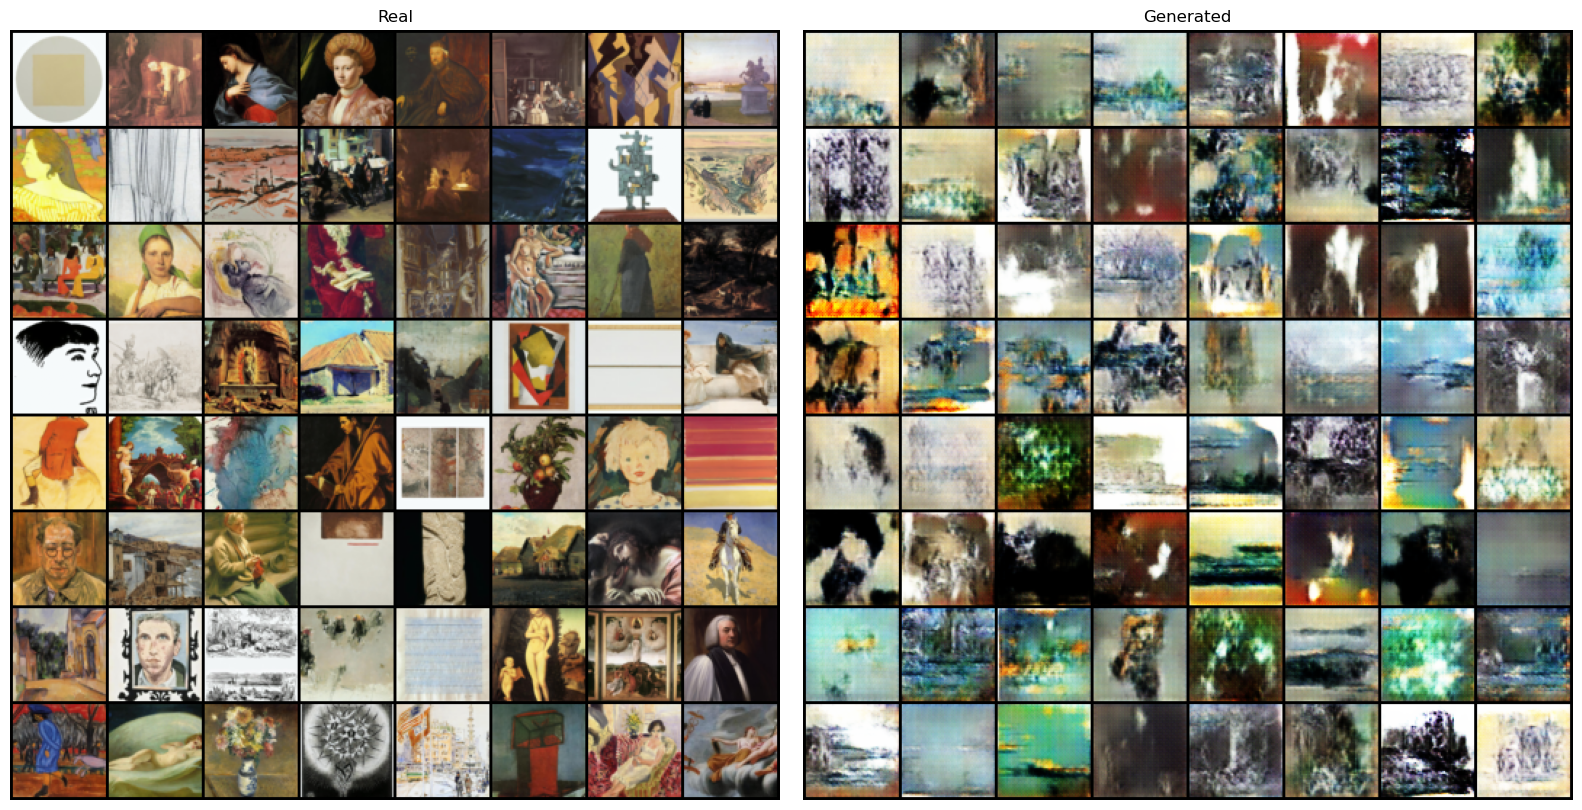

In [10]:
netG.eval()
with torch.no_grad():
    fake = netG(torch.randn(64, NZ, 1, 1, device=device)).cpu()

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(np.transpose(vutils.make_grid(real_batch[0][:64], padding=2, normalize=True), (1, 2, 0)))
ax[0].set_title("Real"); ax[0].axis("off")
ax[1].imshow(np.transpose(vutils.make_grid(fake, padding=2, normalize=True), (1, 2, 0)))
ax[1].set_title("Generated"); ax[1].axis("off")
plt.tight_layout(); plt.savefig("real_vs_fake.png", dpi=200); plt.show()
vutils.save_image(fake, "generated_grid.png", nrow=8, normalize=True)

FID and Inception Score

In [11]:
# FID and IS with pytorch-ignite
fid_metric = FID(device=device)
is_metric  = InceptionScore(device=device, output_transform=lambda x: x[0])

def interpolate(batch):
    batch = (batch.detach().cpu() + 1) / 2          # [-1,1] -> [0,1]
    arr = []
    for img in batch:
        pil_img = transforms.ToPILImage()(img.clamp(0, 1))
        arr.append(transforms.ToTensor()(pil_img.resize((299, 299), Image.BILINEAR)))
    return torch.stack(arr)

def evaluation_step(engine, batch):
    with torch.no_grad():
        netG.eval()
        noise = torch.randn(batch[0].size(0), NZ, 1, 1, device=device)
        return interpolate(netG(noise)), interpolate(batch[0])

evaluator = Engine(evaluation_step)
fid_metric.attach(evaluator, "fid")
is_metric.attach(evaluator, "is")

N_EVAL = 5000
eval_idx = np.random.choice(len(dataset), N_EVAL, replace=False)
eval_loader = DataLoader(Subset(dataset, eval_idx), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

evaluator.run(eval_loader, max_epochs=1)
print(f"[ignite] FID: {evaluator.state.metrics['fid']:.4f}")
print(f"[ignite] IS:  {evaluator.state.metrics['is']:.4f}")

[ignite] FID: 0.0707
[ignite] IS:  2.4283


In [12]:
import os, shutil, torch_fidelity
from torchvision.utils import save_image

N = 5000
real_dir, fake_dir = "/tmp/fid_real", "/tmp/fid_fake"
for d in (real_dir, fake_dir):
    shutil.rmtree(d, ignore_errors=True); os.makedirs(d)

k = 0
for imgs, _ in eval_loader:
    for img in imgs:
        save_image((img + 1) / 2, f"{real_dir}/{k:05d}.png"); k += 1
        if k >= N: break
    if k >= N: break

netG.eval()
k = 0
with torch.no_grad():
    while k < N:
        fake = netG(torch.randn(256, NZ, 1, 1, device=device)).cpu()
        for img in fake:
            save_image((img + 1) / 2, f"{fake_dir}/{k:05d}.png"); k += 1
            if k >= N: break

print(len(os.listdir(real_dir)), "real |", len(os.listdir(fake_dir)), "fake")

# standard FID / IS (TF-Inception weights)
m = torch_fidelity.calculate_metrics(
    input1=fake_dir, input2=real_dir,
    cuda=True, fid=True, isc=True, verbose=False,
)
print(f"FID: {m['frechet_inception_distance']:.2f}")
print(f"IS:  {m['inception_score_mean']:.3f} ± {m['inception_score_std']:.3f}")

5000 real | 5000 fake
FID: 148.55
IS:  2.930 ± 0.109
